# Experiment 3 (v3): Band Selection with a LEAK-FREE evaluation

**Why v3 exists.** In v2 the training noise was fixed (std across seeds about 0.03), but every method reached about 99.95 % with 100 % train accuracy.
That is a symptom of a too-easy test, not of good bands: a random pixel split lets the model see the test pixel's neighbours (overlapping 7x7 patches)
and the test pixel's superpixel (shared graph node) with labels in training.

**What changed compared with v2**

| Change | Why |
|---|---|
| `SPLIT = "group"`: test set = whole superpixels, plus a buffer so no training patch overlaps a test patch | Removes spatial leakage. Use `SPLIT = "pixel"` only to reproduce the old, leaky numbers for comparison. |
| One fixed, label-free segmentation shared by all methods (`GRAPH_SEG = "fixed"`) | The graph regions no longer change with the band set, and test superpixels never contain training labels. |
| Result files are named by split | v2 results are not mixed in. |

**How to run:** GPU runtime, run all cells with `MODE = "check"` (about 10 min). Expect LOWER and more variable accuracy than 99.95 %: that is the honest number.
If the check looks sensible, set `MODE = "full"` in cell 1, re-run cell 1, then cells 7-9.

In [12]:
# CELL 1: IMPORTS + CONFIG
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"      # needed for deterministic CUDA matmuls (set before CUDA starts)

import json, math, time
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import kneighbors_graph
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score, cohen_kappa_score, precision_recall_fscore_support
from skimage.segmentation import slic
from scipy.ndimage import maximum_filter

# ---------------- choose the mode ----------------
MODE = "full"      # "check" = quick noise test (about 10 min on a T4);  "full" = whole experiment (about 1.5 h)

PRESETS = {
    "check": dict(K_LIST=[10], SEEDS=[42, 43, 44], N_RANDOM=0, METHODS=("uniform", "pca"),
                  RUN_ALL_BANDS=False, REF_PCA_K=None),
    "full":  dict(K_LIST=[5, 10, 20, 40], SEEDS=[42, 43], N_RANDOM=3,
                  METHODS=("learned", "anova", "uniform", "pca"),
                  RUN_ALL_BANDS=True, REF_PCA_K=30),
}
cfg = PRESETS[MODE]
K_LIST, SEEDS, N_RANDOM = cfg["K_LIST"], cfg["SEEDS"], cfg["N_RANDOM"]
METHODS, RUN_ALL_BANDS, REF_PCA_K = cfg["METHODS"], cfg["RUN_ALL_BANDS"], cfg["REF_PCA_K"]

# ---------------- same model/graph settings as Experiment 1 ----------------
SEED        = 42
PATCH       = 7
N_SEGMENTS  = 200
KNN_K       = 5
COMPACTNESS = 0.1
VIT_DIM     = 128
GRAPH_DIM   = 64
BATCH_SIZE  = 64

# ---------------- evaluation protocol (NEW in v3) ----------------
SPLIT       = "group"   # "group" = split by whole superpixels + patch buffer (strict). "pixel" = old random split (leaky, for comparison only)
SPLIT_SEED  = 42        # changes WHICH superpixels become test; a different seed gives a different (also valid) split
TEST_FRAC   = 0.3
GRAPH_SEG   = "fixed"   # "fixed" = one label-free segmentation shared by all methods. "per_band_set" = re-run SLIC on the chosen bands

# ---------------- training of every downstream model (changed from v1) ----------------
EPOCHS      = 10            # v1 used 5
LR          = 1e-3          # peak LR; warm-up then cosine decay to ~0
WARMUP_STEPS = 200
CLIP_NORM   = 1.0

# ---------------- learned band selector ----------------
SEL_EPOCHS    = 50
SEL_BATCH     = 256
TAU_START, TAU_END = 10.0, 0.1
LAMBDA_UNIQUE = 0.1         # discourages two neurons choosing the same band
MIN_GAP       = 3           # selected bands must be at least this many bands apart
N_RESTARTS    = 3           # selector restarts; best one chosen on held-out TRAIN pixels (set 1 to disable)
PROXY_EPOCHS  = 15          # epochs of the small pixel-MLP used to score a restart

WAVELENGTHS   = None        # optional array of length = number of bands (nm) for the plots

# ---------------- reproducibility ----------------
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)    # warns (does not crash) if an op has no deterministic version
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| MODE:", MODE)
if device.type == "cpu":
    print("WARNING: running on CPU. Switch the runtime to a T4 GPU (Runtime > Change runtime type) before continuing.")

Device: cuda | MODE: full


In [2]:
# CELL 2: DATASET LOADING (upload the .mat files: data + ground truth)
def load_dataset_auto():
    from google.colab import files
    uploaded = files.upload()
    hsi, gt = None, None

    for fname in uploaded.keys():
        if fname.endswith(".mat"):
            data = sio.loadmat(fname)
            for k, v in data.items():
                if k.startswith("__") or not isinstance(v, np.ndarray):
                    continue
                if v.ndim == 3 and hsi is None:          # (H, W, bands)
                    hsi = v
                elif v.ndim == 2 and "gt" in k.lower():  # (H, W) labels
                    gt = v
        elif fname.endswith(".npy"):
            arr = np.load(fname)
            if "gt" in fname.lower():
                gt = arr
            else:
                hsi = arr

    if hsi is None or gt is None:
        raise ValueError("Could not detect dataset. Upload both the HSI cube and the ground-truth file.")

    hsi = hsi.astype(np.float32)
    gt = gt.astype(np.int64)
    print("HSI shape:", hsi.shape, "| GT shape:", gt.shape)
    print("Classes:", int(gt.max()), "| Labelled pixels:", int((gt > 0).sum()))
    return hsi, gt

hsi, gt = load_dataset_auto()
H, W, C = hsi.shape
num_classes = int(gt.max())
assert max(K_LIST) <= C and min(K_LIST) >= 3, "band budgets must be between 3 and the number of bands"

Saving salinas_corrected.mat to salinas_corrected.mat
Saving salinas_gt.mat to salinas_gt.mat
HSI shape: (512, 217, 204) | GT shape: (512, 217)
Classes: 16 | Labelled pixels: 54129


In [3]:
# CELL 3: TRAIN/TEST SPLIT (spatially disjoint when SPLIT = "group")
rows, cols = np.nonzero(gt)
labels = gt[rows, cols] - 1                      # 0..num_classes-1
all_idx = np.arange(len(labels))


def reference_superpixels():
    """One label-free segmentation of the whole scene, shared by every method (and used as the graph's regions)."""
    flat = hsi.reshape(-1, C)
    z = (flat - flat.mean(0)) / (flat.std(0) + 1e-8)
    p3 = PCA(n_components=3, random_state=SEED).fit_transform(z).reshape(H, W, 3)
    p3 = (p3 - p3.min(axis=(0, 1))) / (p3.max(axis=(0, 1)) - p3.min(axis=(0, 1)) + 1e-8)
    seg = slic(p3, n_segments=N_SEGMENTS, compactness=COMPACTNESS,
               convert2lab=False, channel_axis=-1, start_label=0)
    _, seg = np.unique(seg, return_inverse=True)
    return seg.reshape(H, W)

ref_seg = reference_superpixels()
print("Reference superpixels:", int(ref_seg.max()) + 1)

if SPLIT == "pixel":
    train_idx, test_idx = train_test_split(all_idx, test_size=TEST_FRAC, stratify=labels, random_state=SPLIT_SEED)
else:
    group = ref_seg[rows, cols]                               # superpixel of every labelled pixel
    n_groups = int(ref_seg.max()) + 1
    cnt = np.zeros((n_groups, num_classes), dtype=np.int64)
    np.add.at(cnt, (group, labels), 1)
    total = cnt.sum(0).astype(float)
    target = TEST_FRAC * total
    test_cnt = np.zeros(num_classes)
    rng_split = np.random.RandomState(SPLIT_SEED)
    test_groups = []
    for g in rng_split.permutation(np.nonzero(cnt.sum(1))[0]):
        cg = cnt[g]
        present = cg > 0
        needs = (test_cnt[present] < target[present]).any()               # helps a class that still needs test pixels
        safe = ((test_cnt + cg)[present] <= 0.6 * total[present]).all()   # never leaves a class with <40% of its pixels for training
        if needs and safe:
            test_groups.append(g)
            test_cnt += cg
    is_test = np.isin(group, test_groups)

    # buffer: drop every training pixel whose PATCH x PATCH window could overlap a test pixel's window
    test_map = np.zeros((H, W), dtype=np.uint8)
    test_map[rows[is_test], cols[is_test]] = 1
    near_test = maximum_filter(test_map, size=2 * (PATCH - 1) + 1) > 0
    train_mask = (~is_test) & (~near_test[rows, cols])
    train_idx, test_idx = all_idx[train_mask], all_idx[is_test]
    print("Training pixels dropped by the buffer:", int((~is_test).sum() - train_mask.sum()))

tr_c = np.bincount(labels[train_idx], minlength=num_classes)
te_c = np.bincount(labels[test_idx], minlength=num_classes)
print(f"SPLIT={SPLIT} | Train: {len(train_idx)} | Test: {len(test_idx)} ({len(test_idx) / len(labels) * 100:.1f}% of labelled pixels)")
print("Per-class (train, test):", list(zip(tr_c.tolist(), te_c.tolist())))
if (tr_c == 0).any():
    print("WARNING: classes with NO training pixels:", np.where(tr_c == 0)[0].tolist())
if (te_c == 0).any():
    print("Note: classes with NO test pixels (left out of AA):", np.where(te_c == 0)[0].tolist())

Reference superpixels: 170
Training pixels dropped by the buffer: 12775
SPLIT=group | Train: 20940 | Test: 20414 (37.7% of labelled pixels)
Per-class (train, test): [(1068, 660), (1675, 1295), (599, 825), (491, 551), (683, 1339), (1093, 1854), (1286, 1414), (4502, 3745), (3528, 2082), (1389, 1053), (242, 578), (474, 1055), (197, 466), (311, 625), (2314, 2371), (1088, 501)]


In [4]:
# CELL 4: EXPERIMENT 1 MODEL (ViT branch + GCN/Graph-Transformer branch + fusion), unchanged
class PatchEmbedding(nn.Module):
    def __init__(self, in_channels, embed_dim, n_tokens=PATCH * PATCH):
        super().__init__()
        self.proj = nn.Conv2d(in_channels, embed_dim, 3, padding=1)
        self.pos = nn.Parameter(torch.randn(1, n_tokens, embed_dim) * 0.02)

    def forward(self, x):                                   # (B, C, 7, 7)
        x = self.proj(x).flatten(2).transpose(1, 2)         # (B, 49, dim)
        return x + self.pos

class ViTEncoder(nn.Module):
    def __init__(self, dim, heads=4, layers=2):
        super().__init__()
        layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=dim * 2,
                                           dropout=0.1, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return self.norm(self.encoder(x)).mean(dim=1)       # (B, dim)

class GCNLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim)

    def forward(self, X, A_hat):                            # A_hat is pre-normalised
        return F.relu(self.linear(A_hat @ X))

class GraphTransformer(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm1 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 2), nn.ReLU(), nn.Linear(dim * 2, dim))
        self.norm2 = nn.LayerNorm(dim)

    def forward(self, x):                                   # x: (N_nodes, dim)
        x = x.unsqueeze(0)
        a, _ = self.attn(x, x, x)                           # attention over all nodes
        x = self.norm1(x + a)
        x = self.norm2(x + self.ffn(x))
        return x.squeeze(0)                                 # (N_nodes, dim)

class HSIModel(nn.Module):
    def __init__(self, in_channels, vit_dim, graph_dim, num_classes):
        super().__init__()
        self.patch_embed = PatchEmbedding(in_channels, vit_dim)
        self.vit = ViTEncoder(vit_dim)
        self.gcn1 = GCNLayer(in_channels, graph_dim)
        self.gcn2 = GCNLayer(graph_dim, graph_dim)
        self.graph_trans = GraphTransformer(graph_dim)
        self.fusion = nn.Sequential(nn.Linear(vit_dim + graph_dim, 128), nn.ReLU(), nn.Dropout(0.3))
        self.cls = nn.Linear(128, num_classes)

    def forward(self, patch, seg_ids, node_feats, A_hat):
        vit_feat = self.vit(self.patch_embed(patch))                    # (B, 128) pixel-level
        g = self.gcn2(self.gcn1(node_feats, A_hat), A_hat)              # (N, 64)
        g = self.graph_trans(g)                                         # (N, 64) region-level
        graph_feat = g[seg_ids]                                         # (B, 64) superpixel of each pixel
        fused = self.fusion(torch.cat([vit_feat, graph_feat], dim=-1))
        return self.cls(fused)

In [5]:
# CELL 5: STANDARDISE (TRAIN pixels only) + BAND SELECTORS (learned, ANOVA, uniform, random, PCA)
r_tr, c_tr = rows[train_idx], cols[train_idx]
y_train = labels[train_idx]
pix_train = hsi[r_tr, c_tr].astype(np.float32)
scaler = StandardScaler().fit(pix_train)
pix_train_std = scaler.transform(pix_train).astype(np.float32)
Xs = scaler.transform(hsi.reshape(-1, C)).astype(np.float32).reshape(H, W, C)


def class_weights(y):
    cc = np.bincount(y, minlength=num_classes)
    return torch.tensor(len(y) / (num_classes * np.maximum(cc, 1)), dtype=torch.float32, device=device)


class ConcreteSelector(nn.Module):
    """k selector neurons, each a softmax over all bands. Training: Gumbel-softmax (soft, annealed).
    Final selection: argmax of every neuron."""
    def __init__(self, n_bands, k):
        super().__init__()
        self.logits = nn.Parameter(torch.randn(k, n_bands) * 0.01)

    def forward(self, x, tau):
        if self.training:
            u = torch.rand_like(self.logits).clamp(1e-9, 1 - 1e-9)
            g = -torch.log(-torch.log(u))
            p = F.softmax((self.logits + g) / tau, dim=1)       # (k, C)
        else:
            p = F.one_hot(self.logits.argmax(1), self.logits.size(1)).float()
        return x @ p.T, p                                        # (B, k), (k, C)


class SelectorNet(nn.Module):
    def __init__(self, n_bands, k, n_classes):
        super().__init__()
        self.sel = ConcreteSelector(n_bands, k)
        self.mlp = nn.Sequential(nn.Linear(k, 128), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, n_classes))

    def forward(self, x, tau):
        z, p = self.sel(x, tau)
        return self.mlp(z), p


@torch.no_grad()
def resolve_selection(logits, min_gap=MIN_GAP):
    """k DISTINCT bands, at least `min_gap` apart where possible. The most confident neuron picks first."""
    k, n_bands = logits.shape
    gap = max(1, min(min_gap, n_bands // k))
    order = logits.max(dim=1).values.argsort(descending=True).tolist()
    chosen, used = [None] * k, set()
    blocked = torch.zeros(n_bands, dtype=torch.bool)
    for n in order:
        for b in logits[n].argsort(descending=True).tolist():
            if not blocked[b]:
                chosen[n] = b
                used.add(b)
                blocked[max(0, b - gap + 1): b + gap] = True
                break
        if chosen[n] is None:                                    # fallback: ignore the gap rule
            for b in logits[n].argsort(descending=True).tolist():
                if b not in used:
                    chosen[n] = b
                    used.add(b)
                    break
    return sorted(chosen)


def learn_bands_once(k, seed, tr_i):
    torch.manual_seed(seed)
    net = SelectorNet(C, k, num_classes).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(y_train[tr_i]))
    opt = torch.optim.Adam([{"params": net.sel.parameters(), "lr": 1e-2},
                            {"params": net.mlp.parameters(), "lr": 1e-3}])
    loader = DataLoader(TensorDataset(torch.from_numpy(pix_train_std[tr_i]),
                                      torch.from_numpy(y_train[tr_i]).long()),
                        batch_size=SEL_BATCH, shuffle=True, generator=torch.Generator().manual_seed(seed))
    for epoch in range(SEL_EPOCHS):
        tau = TAU_START * (TAU_END / TAU_START) ** (epoch / max(SEL_EPOCHS - 1, 1))
        net.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out, p = net(xb, tau)
            loss = loss_fn(out, yb) + LAMBDA_UNIQUE * F.relu(p.sum(0) - 1).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
    return resolve_selection(net.sel.logits.detach().cpu())


def proxy_score(bands, tr_i, va_i, seed):
    """Quality of a band set: balanced accuracy of a small pixel-MLP on HELD-OUT TRAIN pixels (test set unused)."""
    torch.manual_seed(seed)
    x_all = torch.from_numpy(pix_train_std[:, bands])
    y_all = torch.from_numpy(y_train).long()
    mlp = nn.Sequential(nn.Linear(len(bands), 128), nn.ReLU(), nn.Dropout(0.2),
                        nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, num_classes)).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(y_train[tr_i]))
    opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(x_all[tr_i], y_all[tr_i]), batch_size=SEL_BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    for _ in range(PROXY_EPOCHS):
        mlp.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(mlp(xb), yb).backward()
            opt.step()
    mlp.eval()
    with torch.no_grad():
        pred = mlp(x_all[va_i].to(device)).argmax(1).cpu().numpy()
    _, rec, _, sup = precision_recall_fscore_support(y_train[va_i], pred, labels=list(range(num_classes)),
                                                     zero_division=0)
    return rec[sup > 0].mean()


def learn_bands(k, seed):
    """Learned selection: several restarts, keep the one with the best held-out-TRAIN score."""
    strat = y_train if np.bincount(y_train, minlength=num_classes).min() >= 2 else None
    tr_i, va_i = train_test_split(np.arange(len(y_train)), test_size=0.15, stratify=strat, random_state=seed)
    best = None
    for r in range(N_RESTARTS):
        bands = learn_bands_once(k, seed * 100 + r, tr_i)
        score = proxy_score(bands, tr_i, va_i, seed)
        print(f"           restart {r}: held-out balanced acc {score * 100:.2f} | bands {bands if k <= 20 else '...'}")
        if best is None or score > best[0]:
            best = (score, bands)
    return best[1]


def get_features(method, k, seed, d=0):
    """Returns (cube of shape (H, W, k), selected band indices or None)."""
    if method == "learned":
        bands = learn_bands(k, seed)
    elif method == "anova":
        f, _ = f_classif(pix_train_std, y_train)
        bands = sorted(np.argsort(np.nan_to_num(f))[::-1][:k].tolist())
    elif method == "uniform":
        bands = np.linspace(0, C - 1, k).round().astype(int).tolist()
    elif method == "random":
        bands = sorted(np.random.RandomState(1000 + d).choice(C, k, replace=False).tolist())
    elif method == "pca":                                        # reference: needs ALL bands at acquisition
        pca = PCA(n_components=k, random_state=SEED).fit(pix_train_std)
        Z = pca.transform(Xs.reshape(-1, C)) / pca.transform(pix_train_std).std()
        return Z.astype(np.float32).reshape(H, W, k), None
    else:                                                        # "all bands"
        return Xs, list(range(C))
    return np.ascontiguousarray(Xs[:, :, bands]), [int(b) for b in bands]

In [6]:
# CELL 6: GRAPH FROM THE CHOSEN FEATURES + STABILISED TRAINING / EVALUATION OF THE EXPERIMENT-1 MODEL
def make_graph(Xk):
    """SLIC on the first 3 PCs of the CHOSEN features only, node feature = mean of the k channels, kNN graph."""
    h, w, kk = Xk.shape
    if GRAPH_SEG == "fixed":
        seg = ref_seg                                     # same label-free regions for every method
    else:
        p3 = PCA(n_components=3, random_state=SEED).fit_transform(Xk.reshape(-1, kk)).reshape(h, w, 3)
        p3 = (p3 - p3.min(axis=(0, 1))) / (p3.max(axis=(0, 1)) - p3.min(axis=(0, 1)) + 1e-8)
        seg = slic(p3, n_segments=N_SEGMENTS, compactness=COMPACTNESS,
                   convert2lab=False, channel_axis=-1, start_label=0)
        _, seg = np.unique(seg, return_inverse=True)
        seg = seg.reshape(h, w)
    n = int(seg.max()) + 1
    flat = seg.ravel()
    counts = np.bincount(flat, minlength=n).astype(np.float32)
    feats = np.stack([np.bincount(flat, weights=Xk[:, :, c].ravel(), minlength=n) / counts
                      for c in range(kk)], axis=1).astype(np.float32)
    A = kneighbors_graph(feats, KNN_K, mode="connectivity", include_self=False).toarray()
    A = np.maximum(A, A.T) + np.eye(n)
    d = 1.0 / np.sqrt(A.sum(axis=1))
    A_hat = A * d[:, None] * d[None, :]
    return torch.tensor(feats).float(), torch.tensor(A_hat).float(), torch.tensor(seg).long()


class BandPatchDS(Dataset):
    def __init__(self, Xp, seg, idx):
        self.Xp, self.seg, self.idx = Xp, seg, idx
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        r, c = rows[j], cols[j]
        patch = torch.from_numpy(self.Xp[r:r + PATCH, c:c + PATCH]).permute(2, 0, 1)
        return patch, self.seg[r, c], torch.tensor(labels[j])


def train_eval(Xk, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    kk = Xk.shape[2]
    node_f, A_h, seg = make_graph(Xk)
    node_f, A_h = node_f.to(device), A_h.to(device)
    p_ = PATCH // 2
    Xp = np.pad(Xk, ((p_, p_), (p_, p_), (0, 0)), mode="reflect")

    tr_loader = DataLoader(BandPatchDS(Xp, seg, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                           generator=torch.Generator().manual_seed(seed))
    te_loader = DataLoader(BandPatchDS(Xp, seg, test_idx), batch_size=256, shuffle=False)

    m = HSIModel(kk, VIT_DIM, GRAPH_DIM, num_classes).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(labels[train_idx]))
    opt = torch.optim.Adam(m.parameters(), lr=LR)

    total_steps = EPOCHS * len(tr_loader)
    warm = max(1, min(WARMUP_STEPS, total_steps // 10))
    def lr_lambda(step):                                   # linear warm-up, then cosine decay to ~0
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1.0 + math.cos(math.pi * (step - warm) / max(total_steps - warm, 1)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    last_correct, last_seen = 0, 0
    for epoch in range(EPOCHS):
        m.train()
        for patch, seg_ids, y in tr_loader:
            patch, seg_ids, y = patch.to(device), seg_ids.to(device), y.to(device)
            opt.zero_grad()
            out = m(patch, seg_ids, node_f, A_h)
            loss = loss_fn(out, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), CLIP_NORM)
            opt.step()
            sched.step()
            if epoch == EPOCHS - 1:
                last_correct += (out.argmax(1) == y).sum().item()
                last_seen += len(y)

    m.eval()
    preds, trues = [], []
    with torch.no_grad():
        for patch, seg_ids, y in te_loader:
            out = m(patch.to(device), seg_ids.to(device), node_f, A_h)
            preds.append(out.argmax(1).cpu().numpy())
            trues.append(y.numpy())
    yt, yp = np.concatenate(trues), np.concatenate(preds)
    _, rec, _, sup = precision_recall_fscore_support(yt, yp, labels=list(range(num_classes)), zero_division=0)
    return dict(OA=accuracy_score(yt, yp), AA=rec[sup > 0].mean(), Kappa=cohen_kappa_score(yt, yp),
                train_acc=last_correct / max(last_seen, 1),
                params=sum(p.numel() for p in m.parameters()))

In [13]:
# CELL 7: RUN THE GRID (saved to CSV after every run; if Colab disconnects, re-run cells 1-6 and this cell to resume)
RES_CSV = f"/content/exp3_v3_results_{MODE}_{SPLIT}.csv"
SEL_JSON = f"/content/exp3_v3_selected_{MODE}_{SPLIT}.json"

jobs = []
if RUN_ALL_BANDS:
    jobs.append(("all bands", C, 0))
if REF_PCA_K and REF_PCA_K not in K_LIST:
    jobs.append(("pca", REF_PCA_K, 0))
for k in K_LIST:
    for method in METHODS:
        jobs.append((method, k, 0))
    for d in range(N_RANDOM):
        jobs.append(("random", k, d))

records, selected, done = [], {}, set()
if os.path.exists(RES_CSV):
    records = pd.read_csv(RES_CSV).to_dict("records")
    done = {(r["method"], int(r["k"]), int(r["seed"]), int(r["draw"])) for r in records}
    if os.path.exists(SEL_JSON):
        selected = {tuple(json.loads(key)): v for key, v in json.load(open(SEL_JSON)).items()}
    print(f"Resuming: {len(done)} runs already finished.")

n_total = len(jobs) * len(SEEDS)
print(f"MODE={MODE} | SPLIT={SPLIT} | {len(jobs)} configurations x {len(SEEDS)} seeds = {n_total} runs | {EPOCHS} epochs each\n")

for method, k, d in jobs:
    for s in SEEDS:
        if (method, k, s, d) in done:
            continue
        t0 = time.time()
        Xk, bands = get_features(method, k, s, d)
        sc = train_eval(Xk, s)
        selected[(method, k, s, d)] = bands
        records.append(dict(method=method, k=k, seed=s, draw=d, secs=time.time() - t0, **sc))
        print(f"{method:<10} k={k:<4} seed={s} draw={d} | OA {sc['OA'] * 100:.2f} | AA {sc['AA'] * 100:.2f} "
              f"| Kappa {sc['Kappa'] * 100:.2f} | train acc {sc['train_acc'] * 100:.2f} | {time.time() - t0:.0f}s")
        if bands is not None and method in ("learned", "anova") and len(bands) <= 40:
            print(f"           bands: {bands}")
        pd.DataFrame(records).to_csv(RES_CSV, index=False)
        json.dump({json.dumps(list(key)): v for key, v in selected.items()}, open(SEL_JSON, "w"))

res = pd.DataFrame(records)
print("\nFinished. Results saved to", RES_CSV)

MODE=full | SPLIT=group | 30 configurations x 2 seeds = 60 runs | 10 epochs each

all bands  k=204  seed=42 draw=0 | OA 85.34 | AA 87.65 | Kappa 83.87 | train acc 99.97 | 61s
all bands  k=204  seed=43 draw=0 | OA 87.21 | AA 91.51 | Kappa 85.94 | train acc 99.94 | 56s
pca        k=30   seed=42 draw=0 | OA 91.17 | AA 94.96 | Kappa 90.30 | train acc 100.00 | 49s
pca        k=30   seed=43 draw=0 | OA 91.49 | AA 94.58 | Kappa 90.64 | train acc 100.00 | 48s
           restart 0: held-out balanced acc 92.76 | bands [5, 20, 83, 101, 105]
           restart 1: held-out balanced acc 93.35 | bands [6, 82, 102, 105, 199]
           restart 2: held-out balanced acc 93.63 | bands [8, 18, 83, 102, 150]
learned    k=5    seed=42 draw=0 | OA 87.62 | AA 88.52 | Kappa 86.37 | train acc 100.00 | 101s
           bands: [8, 18, 83, 102, 150]
           restart 0: held-out balanced acc 93.19 | bands [15, 18, 38, 95, 105]
           restart 1: held-out balanced acc 93.98 | bands [17, 82, 95, 104, 199]
       

===== Mean +- std over seeds (and random draws). std uses ddof=1 =====
   method   k            OA            AA         Kappa train acc  runs
    anova   5 81.42 +- 0.88 85.37 +- 0.54 79.66 +- 0.96     97.38     2
  learned   5 88.91 +- 1.83 90.43 +- 2.70 87.79 +- 2.00    100.00     2
      pca   5 87.56 +- 1.22 92.89 +- 0.67 86.32 +- 1.32    100.00     2
   random   5 85.83 +- 1.32 88.26 +- 2.01 84.41 +- 1.45     99.97     6
  uniform   5 86.46 +- 2.09 90.70 +- 1.82 85.09 +- 2.31    100.00     2
    anova  10 81.29 +- 0.05 86.63 +- 0.60 79.55 +- 0.09     99.91     2
  learned  10 87.34 +- 1.87 90.88 +- 0.84 86.08 +- 2.04     99.99     2
      pca  10 88.34 +- 0.74 92.73 +- 0.69 87.17 +- 0.81    100.00     2
   random  10 86.79 +- 1.66 90.59 +- 2.49 85.46 +- 1.84    100.00     6
  uniform  10 87.73 +- 0.67 91.35 +- 0.80 86.50 +- 0.71    100.00     2
    anova  20 82.49 +- 0.42 86.22 +- 0.83 80.93 +- 0.45     99.85     2
  learned  20 85.65 +- 0.54 89.78 +- 1.39 84.24 +- 0.58    100.00

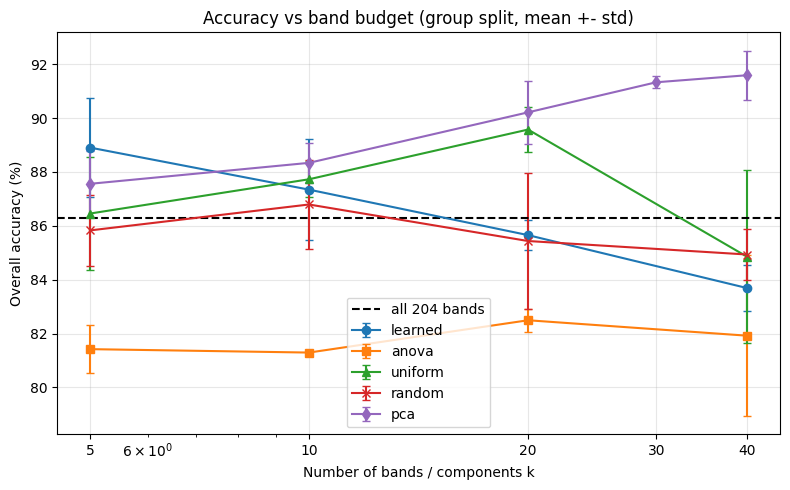

In [14]:
# CELL 8: RESULTS TABLE + OA-vs-k CURVE
def fmt(v):
    v = np.asarray(v) * 100
    return f"{v.mean():.2f} +- {v.std(ddof=1):.2f}" if len(v) > 1 else f"{v.mean():.2f}"

summary_rows = []
for (method, k), g in res.groupby(["method", "k"]):
    summary_rows.append({"method": method, "k": k, "OA": fmt(g["OA"]), "AA": fmt(g["AA"]),
                         "Kappa": fmt(g["Kappa"]), "train acc": f"{g['train_acc'].mean() * 100:.2f}", "runs": len(g)})
summary = pd.DataFrame(summary_rows).sort_values(["k", "method"])
print("===== Mean +- std over seeds (and random draws). std uses ddof=1 =====")
print(summary.to_string(index=False))

print("\n===== Mean OA (%) by method and k =====")
print((res.pivot_table(index="k", columns="method", values="OA", aggfunc="mean") * 100).round(2).to_string())

if MODE == "check":
    print("\n===== NOISE CHECK =====")
    for m_ in ("uniform", "pca"):
        sub = res[res.method == m_]
        if len(sub) > 1:
            print(f"{m_:<8} OA per seed: {np.round(sub.OA.values * 100, 2)} | std = {sub.OA.std(ddof=1) * 100:.2f}")
    print(f"SPLIT = {SPLIT}. With the strict 'group' split expect LOWER accuracy than the 99.9 % of the random split;")
    print("that is the honest number. Send me this output. If it looks sensible, set MODE = 'full' in cell 1,")
    print("re-run cell 1, then re-run cells 7, 8 and 9.")

plt.figure(figsize=(8, 5))
for method, marker in [("learned", "o"), ("anova", "s"), ("uniform", "^"), ("random", "x"), ("pca", "d")]:
    sub = res[res.method == method].groupby("k")["OA"].agg(["mean", "std"]).reset_index()
    if len(sub):
        plt.errorbar(sub["k"], sub["mean"] * 100, yerr=sub["std"].fillna(0) * 100,
                     marker=marker, capsize=3, label=method)
ref = res[res.method == "all bands"]
if len(ref):
    plt.axhline(ref["OA"].mean() * 100, color="k", linestyle="--", label=f"all {C} bands")
ticks = sorted(set(K_LIST) | ({REF_PCA_K} if REF_PCA_K else set()))
plt.xscale("log"); plt.xticks(ticks, [str(k) for k in ticks])
plt.xlabel("Number of bands / components k"); plt.ylabel("Overall accuracy (%)")
plt.title(f"Accuracy vs band budget ({SPLIT} split, mean +- std)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

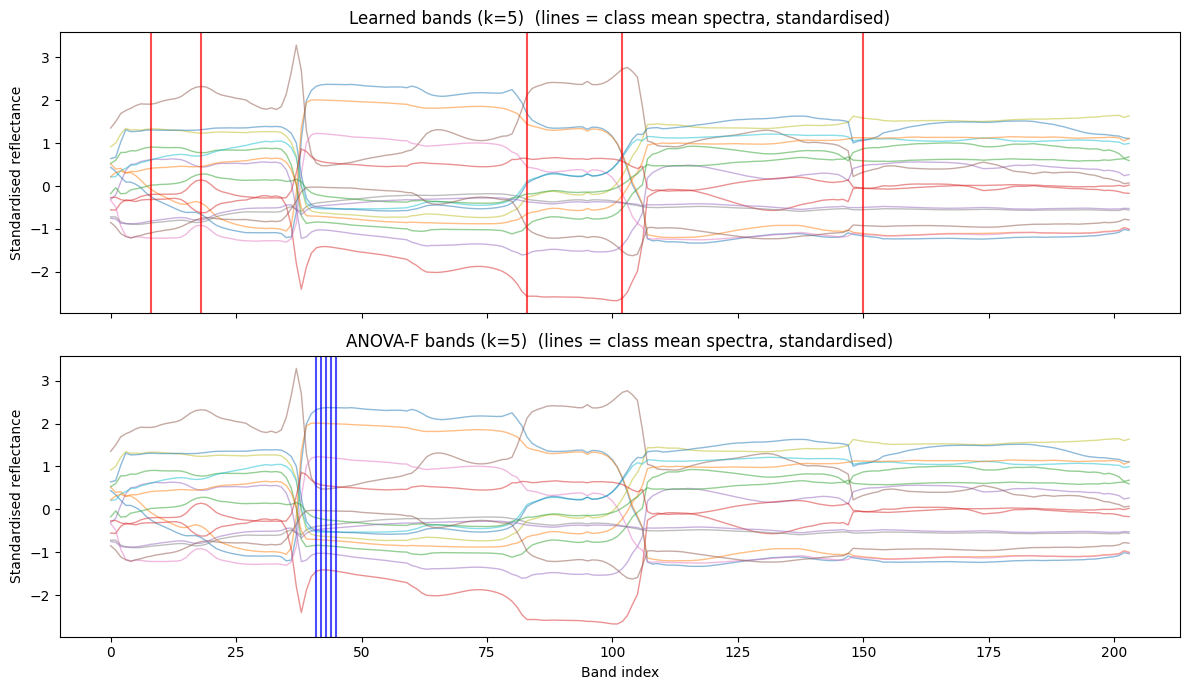

k=5: learned and ANOVA share 0 of 5 bands


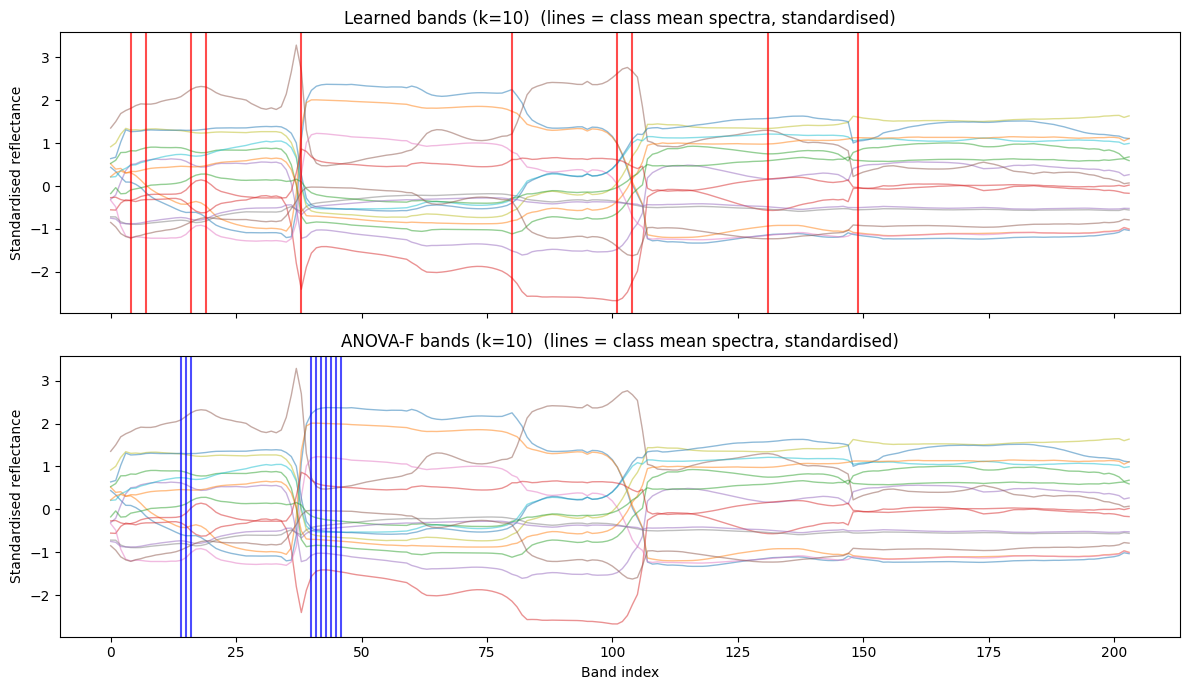

k=10: learned and ANOVA share 1 of 10 bands


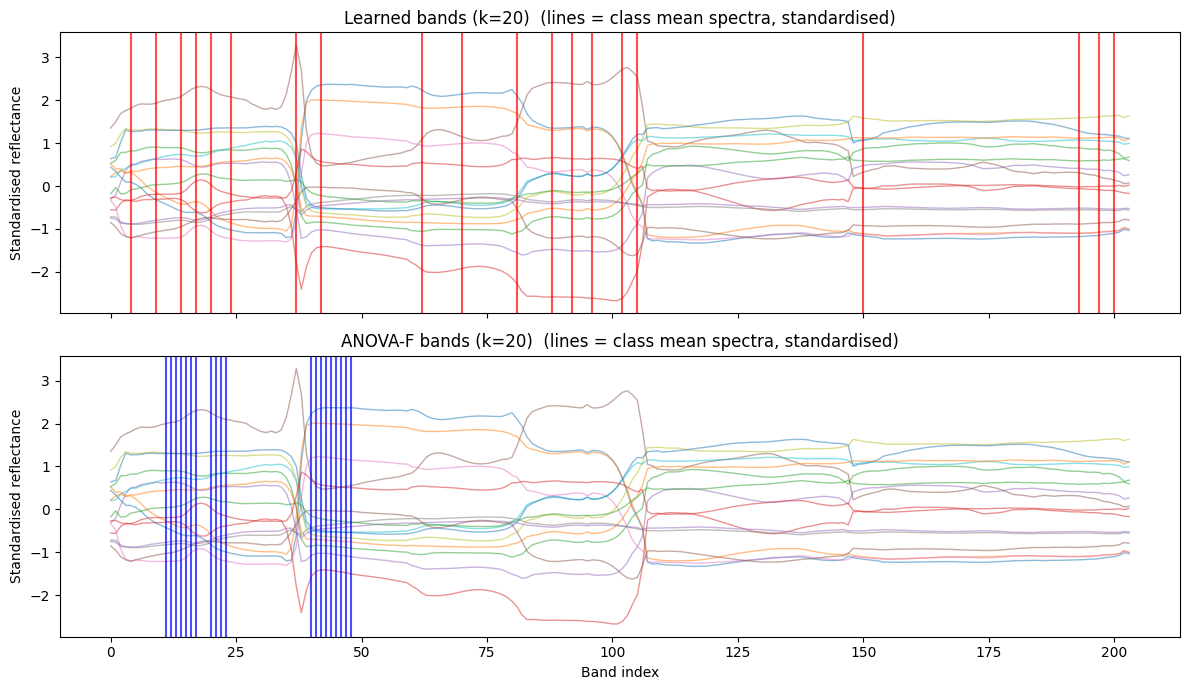

k=20: learned and ANOVA share 4 of 20 bands


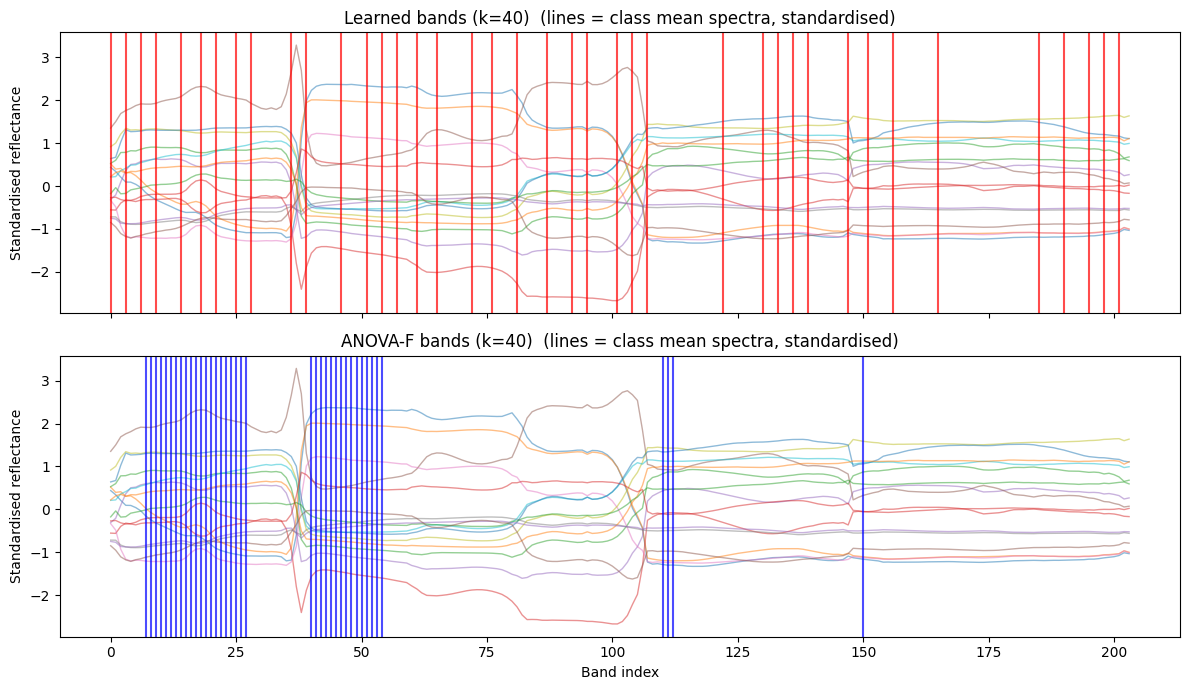

k=40: learned and ANOVA share 8 of 40 bands


In [15]:
# CELL 9: WHERE DO THE SELECTED BANDS SIT ON THE SPECTRUM?
def plot_selection(k, seed=SEEDS[0]):
    x = np.arange(C) if WAVELENGTHS is None else np.asarray(WAVELENGTHS)
    mean_spec = np.stack([pix_train_std[y_train == c].mean(axis=0) for c in range(num_classes)])
    learned = selected.get(("learned", k, seed, 0))
    anova = selected.get(("anova", k, seed, 0))
    fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    for a, bands, title, col in [(ax[0], learned, f"Learned bands (k={k})", "red"),
                                 (ax[1], anova, f"ANOVA-F bands (k={k})", "blue")]:
        for c in range(num_classes):
            a.plot(x, mean_spec[c], alpha=0.5, linewidth=1)
        if bands is not None:
            for b in bands:
                a.axvline(x[b], color=col, alpha=0.7)
        a.set_title(title + "  (lines = class mean spectra, standardised)")
        a.set_ylabel("Standardised reflectance")
    ax[1].set_xlabel("Wavelength (nm)" if WAVELENGTHS is not None else "Band index")
    plt.tight_layout(); plt.show()
    if learned is not None and anova is not None:
        print(f"k={k}: learned and ANOVA share {len(set(learned) & set(anova))} of {k} bands")

for k in K_LIST:
    if ("learned", k, SEEDS[0], 0) in selected:
        plot_selection(k)

### How to read the results
- **Trust a difference only if it is larger than the std** shown in the table. With 2 seeds, treat gaps under about 1 point as ties.
- **Learned vs random / uniform / ANOVA at the same k** is the evidence that *which* bands you pick matters. PCA is a reference only: it needs every band measured.
- **Check the `train acc` column.** If it is low for some k, that setting is under-trained and its OA says little about the bands.
- **Do not claim** "k bands beat all bands" unless the all-bands and PCA-30 references are clearly stable and lower.
- Report which split you used. Numbers from `SPLIT = "pixel"` are inflated by spatial leakage and should not be compared with `"group"` numbers or with papers that use disjoint splits.
- A single split decides which superpixels are test. For the final report, repeat with another `SPLIT_SEED` (for example 43) and compare.
- With `GRAPH_SEG = "fixed"` the region geometry comes from the full spectrum once (label-free), so differences between methods come from the bands, not from the graph. State this assumption in the report.
- Repeat on Indian Pines for a harder test.